# EV Spare Parts Sales Analysis (Jun – Sep 2026)
Sales of EV two-wheeler spare parts to EV repair shops in Maharashtra, Gujarat and Karnataka.
Orders come on WhatsApp Business or by direct call, and parts are shipped to the shop.

*Sample data: shop names and orders are made up.*

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Load the data

In [2]:
orders = pd.read_csv('../data/orders.csv')
items = pd.read_csv('../data/order_items.csv')
customers = pd.read_csv('../data/customers.csv')
cities = pd.read_csv('../data/cities.csv')
parts = pd.read_csv('../data/parts.csv')

print('Orders:', len(orders))
print('Order lines:', len(items))
print('Repair shops:', len(customers))
print('Parts:', len(parts))

Orders: 610
Order lines: 1456
Repair shops: 150
Parts: 38


In [3]:
# join all tables into one table
df = items.merge(orders, on='order_id')
df = df.merge(customers, on='customer_id')
df = df.merge(cities, on='city_id')
df = df.merge(parts, on='part_id')

# month column, e.g. 2026-06
df['month'] = df['order_date'].str[:7]

# check for missing values
print(df.isnull().sum().sum(), 'missing values')
df.head()

0 missing values


,line_id,order_id,part_id,quantity,unit_price,discount_pct,returned_qty,net_amount,order_date,customer_id,...,state,launch_month,region,part_name,part_type,category,variant,list_price,unit_cost,month
0,L000001,O00001,P030,1,950,1.8,0,932.9,2026-06-05,S0045,...,Maharashtra,2026-06,West,Side Panel - Right - Unpainted,Side Panel,Body (Fiber),Right - Unpainted,950,570,2026-06
1,L000002,O00001,P014,1,1350,3.4,0,1304.1,2026-06-05,S0045,...,Maharashtra,2026-06,West,DC-DC Converter - 72V,DC-DC Converter,Electronics,72V,1350,820,2026-06
2,L000003,O00002,P013,1,1200,0.1,0,1198.8,2026-06-05,S0045,...,Maharashtra,2026-06,West,DC-DC Converter - 60V,DC-DC Converter,Electronics,60V,1200,760,2026-06
3,L000004,O00002,P023,2,650,2.4,0,1268.8,2026-06-05,S0045,...,Maharashtra,2026-06,West,Combination Switch - Right,Combination Switch,Electrical,Right,650,380,2026-06
4,L000005,O00002,P015,2,1400,0.7,1,2780.4,2026-06-05,S0045,...,Maharashtra,2026-06,West,Motor PCB,Motor PCB,Electronics,Standard,1400,820,2026-06


## 2. Monthly sales

In [4]:
monthly = df.groupby('month')['net_amount'].sum()
monthly_lakh = (monthly / 100000).round(1)
growth = (monthly.pct_change() * 100).round(0)

print(pd.DataFrame({'sales (Rs lakh)': monthly_lakh, 'growth %': growth}))

         sales (Rs lakh)  growth %
month                             
2026-06              3.0       NaN
2026-07              8.5     181.0
2026-08             16.1      89.0
2026-09             26.0      61.0


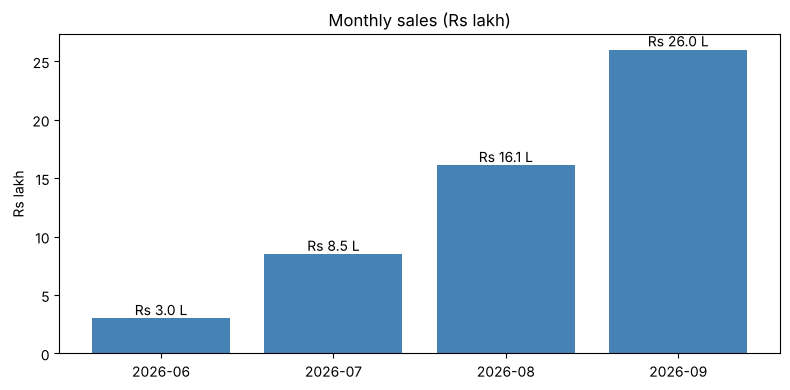

In [5]:
plt.figure(figsize=(8, 4))
bars = plt.bar(monthly_lakh.index, monthly_lakh.values, color='steelblue')
plt.bar_label(bars, labels=['Rs ' + str(v) + ' L' for v in monthly_lakh.values])
plt.title('Monthly sales (Rs lakh)')
plt.ylabel('Rs lakh')
plt.tight_layout()
plt.savefig('../images/monthly_revenue.png')
plt.show()

## 3. Sales by state

In [6]:
state = df.groupby('state')['net_amount'].sum().sort_values(ascending=False)
print((state / state.sum() * 100).round(1))

state
Maharashtra    43.4
Karnataka      34.4
Gujarat        22.2
Name: net_amount, dtype: float64


state    Gujarat  Karnataka  Maharashtra
month                                   
2026-06     21.5       26.2         52.3
2026-07     22.9       29.4         47.7
2026-08     23.1       33.8         43.1
2026-09     21.6       37.4         41.0


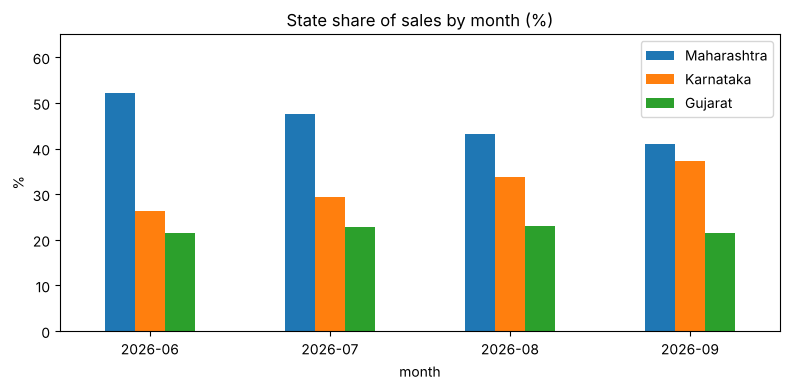

In [7]:
# share of each state in every month
state_month = df.pivot_table(index='month', columns='state', values='net_amount', aggfunc='sum')
state_share = state_month.div(state_month.sum(axis=1), axis=0) * 100
print(state_share.round(1))

state_share[['Maharashtra', 'Karnataka', 'Gujarat']].plot(kind='bar', figsize=(8, 4))
plt.title('State share of sales by month (%)')
plt.ylabel('%')
plt.ylim(0, 65)
plt.legend(loc='upper right')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../images/revenue_by_state.png')
plt.show()

## 4. Parts

In [8]:
category = df.groupby('category')['net_amount'].sum().sort_values(ascending=False)
print((category / 100000).round(1))

category
Battery         17.1
Electronics     14.9
Motor            7.7
Electrical       4.7
Body (Fiber)     4.1
Charging         2.8
Brakes           2.5
Name: net_amount, dtype: float64


In [9]:
top_parts = df.groupby('part_type')['net_amount'].sum().sort_values(ascending=False).head(10)
print((top_parts / 100000).round(2))

part_type
Battery 35Ah              7.20
Battery 30Ah              6.77
Controller                5.31
Hub Motor Set             4.82
Motor PCB                 3.64
Battery 45Ah              3.11
Charger Gun with Cable    2.84
L.V. Cable                2.52
BMS                       2.49
Combination Switch        2.14
Name: net_amount, dtype: float64


variant       LFP  NMC
part_type             
Battery 30Ah   23    8
Battery 35Ah   19   10
Battery 45Ah    7    3


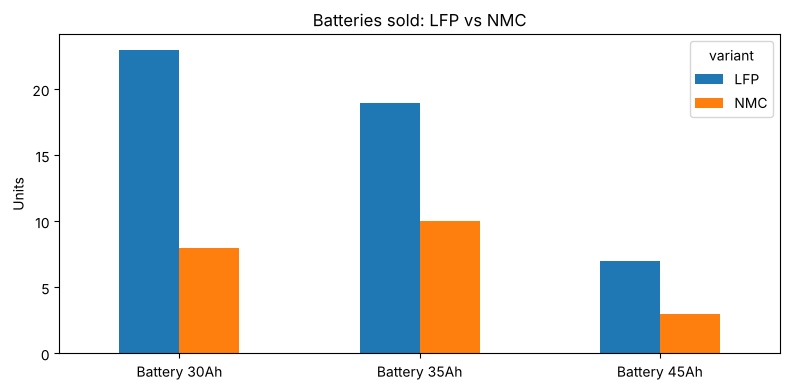

In [10]:
# batteries: 30Ah / 35Ah / 45Ah, LFP vs NMC
battery = df[df['category'] == 'Battery']
battery_units = battery.pivot_table(index='part_type', columns='variant', values='quantity', aggfunc='sum')
print(battery_units)

battery_units.plot(kind='bar', figsize=(8, 4))
plt.title('Batteries sold: LFP vs NMC')
plt.ylabel('Units')
plt.xlabel('')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../images/battery_mix.png')
plt.show()

## 5. Order channel: WhatsApp Business vs Direct Call

channel  Direct Call  WhatsApp Business
month                                  
2026-06           17                 27
2026-07           21                 62
2026-08           61                135
2026-09           98                189


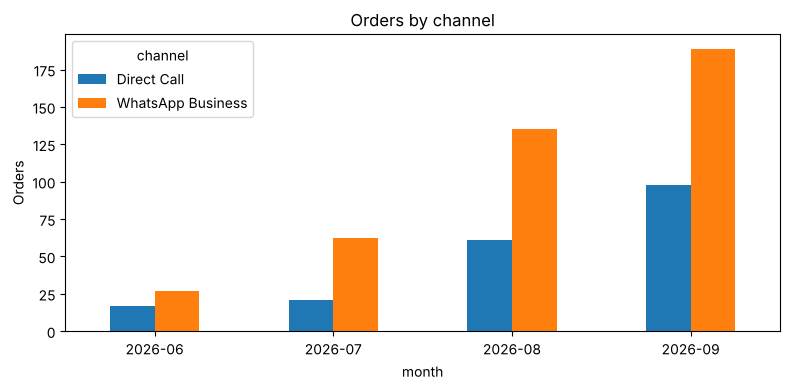

In [11]:
orders['month'] = orders['order_date'].str[:7]
channel = orders.pivot_table(index='month', columns='channel', values='order_id', aggfunc='count')
print(channel)

channel.plot(kind='bar', figsize=(8, 4))
plt.title('Orders by channel')
plt.ylabel('Orders')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../images/channel_mix.png')
plt.show()

## 6. Repair shops

In [12]:
# sales by shop size: A = large, B = medium, C = small
tier = df.groupby('tier').agg(shops=('customer_id', 'nunique'), sales=('net_amount', 'sum'))
tier['share %'] = (tier['sales'] / tier['sales'].sum() * 100).round(1)
print(tier)

      shops       sales  share %
tier                            
A        30  3108015.93     57.8
B        48  1380378.45     25.7
C        72   886485.00     16.5


In [13]:
# shops with no order in September (last order before 1 Sep 2026)
last_order = df.groupby(['shop_name', 'city'])['order_date'].max().reset_index()
no_recent_order = last_order[last_order['order_date'] < '2026-09-01']
print(len(no_recent_order), 'shops to call')
no_recent_order.sort_values('order_date')

26 shops to call


,shop_name,city,order_date
147,Zen Auto Care,Surat,2026-06-15
140,Vision Moto Care,Mumbai,2026-07-18
50,Jai EV Garage,Mumbai,2026-07-22
149,Zen E-Bike Point,Thane,2026-08-03
124,Swift Moto Service Centre,Navi Mumbai,2026-08-05
26,E-Wheels Motors Clinic,Surat,2026-08-06
30,Eco E-Bike Garage,Vadodara,2026-08-08
81,Rapid E-Bike Service Centre,Surat,2026-08-08
115,Spark Two Wheeler Service Centre,Surat,2026-08-10
79,Prime Electric Studio,Thane,2026-08-11


## 7. Findings
1. Sales grew every month: Rs 3.0 lakh in June to Rs 26.0 lakh in September.
2. Karnataka share went up every month (26% → 37%), Maharashtra share went down (52% → 41%).
3. Batteries are the biggest category; LFP batteries sell more than NMC.
4. About two-thirds of orders come on WhatsApp Business.
5. 30 large (A) repair shops give 58% of sales – these are key accounts.
6. 26 shops have not ordered since August – call list for follow-up.